# 1-DOF pitch while HOVERING (doublets): simulation fit and inverse PINN
ANT-X 2-DOF rig, cart locked, only pitch moves. Doublet flights: motors at hover thrust (~0.43), controller off, a push one way then the other (0.3 s each). About 1.4 s later the drone tips over and the motors kick it back, so only the part before that kick is used. This is a separate model from the impulse one (motors off), because thrust changes how the drone swings.

**One physics equation** (ANT-X 1-DOF model), used by every model below:

theta'' = -2 xi wn q - wn^2 (theta - th0) + mu M(t - tau)

| symbol | meaning | unit |
|---|---|---|
| theta, q | pitch angle, pitch rate | rad, rad/s |
| M | pitch command = front motor - back motor | normalised |
| wn | natural frequency (how fast it swings) | rad/s |
| xi | damping ratio (how fast the swing dies) | - |
| mu | input gain (how hard M pushes) | rad/s^2 |
| th0 | rest angle | rad |
| tau | delay command -> motors = 0.02 s (ANT-X) | s |

Train flights: doublet_1 to doublet_5. Test flight: doublet_6 (never seen in training).

## 0. Setup

In [1]:
import numpy as np, pandas as pd, torch, time, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
torch.set_num_threads(4)
D = '../data/1dof/'                      # folder with the csv tables
FL = pd.read_csv(D + 'flights_1dof.csv').set_index('file')
TAU = 0.02                               # delay [s]
WIN = 1.5                                # longest window used per flight (before the kick-back)
TRAIN = ['doublet_1.csv', 'doublet_2.csv', 'doublet_3.csv', 'doublet_4.csv', 'doublet_5.csv']
TEST = 'doublet_6.csv'
ANTX = dict(wn=3.437, xi=0.0836, mu=358.5)   # published ANT-X values (different rig)

## 1. Data: cut each flight from the push to just before the motor kick-back

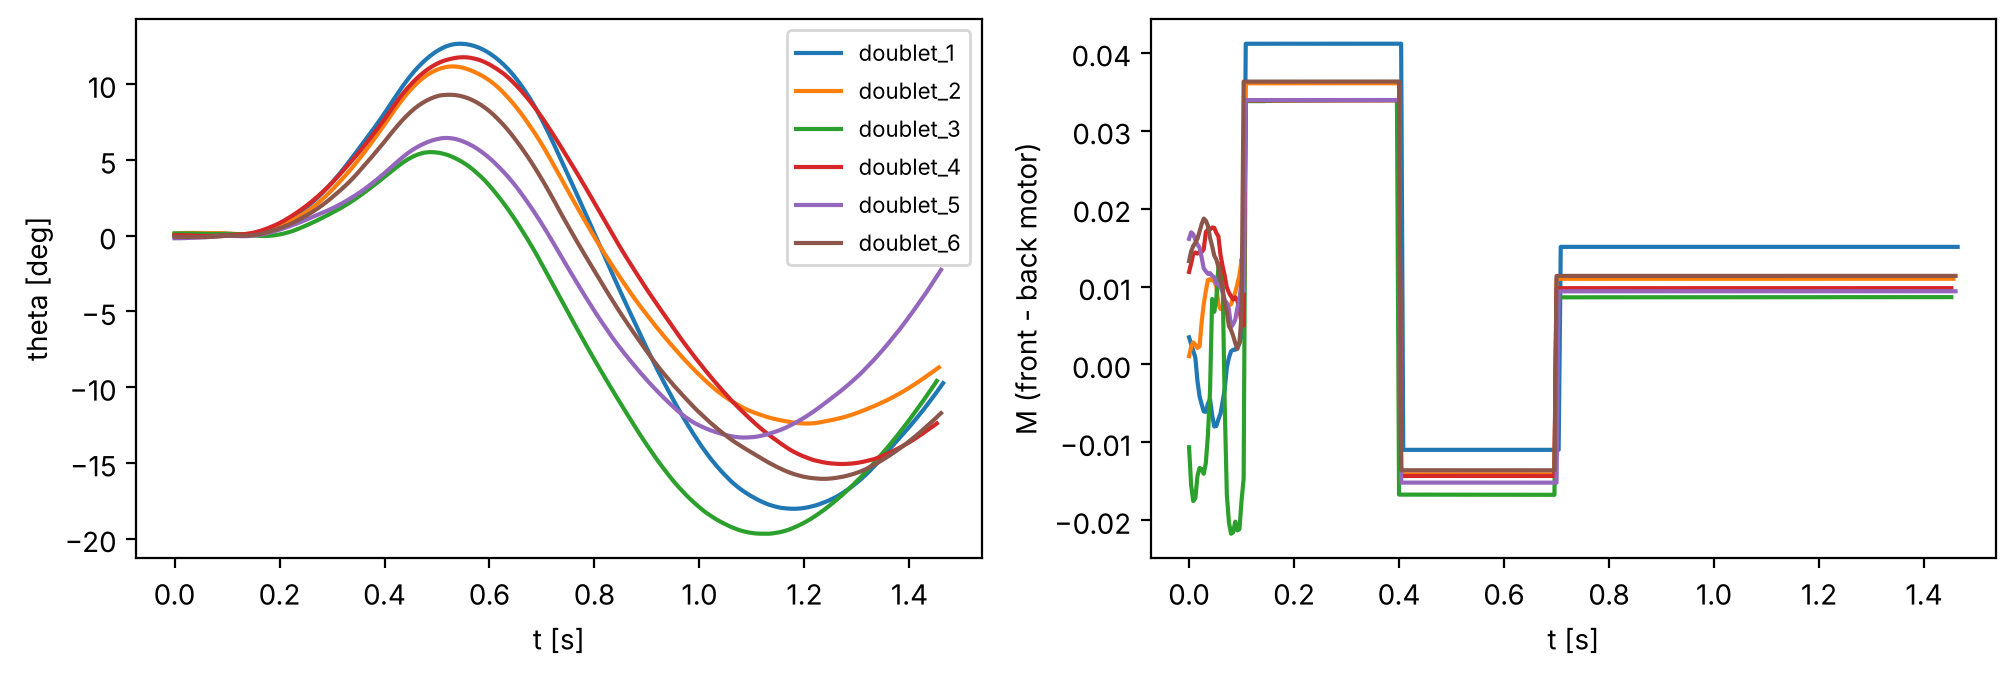

In [2]:
def load(name):
    r = FL.loc[name]
    df = pd.read_csv(D + name)
    after = df[df.t > r.inj_start_s + 0.7]
    kick = after.t[after.M.abs() > 0.12].iloc[0]                          # first big motor kick-back
    w = (df.t >= r.inj_start_s - 0.1) & (df.t < kick - 0.05)               # 0.1 s before the push until just before the kick
    f = df[w].reset_index(drop=True)
    f['t'] = f.t - f.t[0]                                              # time starts at 0
    return f

flights = {n: load(n) for n in TRAIN + [TEST]}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for n, f in flights.items():
    ax[0].plot(f.t, np.degrees(f.theta), label=n.replace('.csv', ''))
    ax[1].plot(f.t, f.M)
ax[0].set(xlabel='t [s]', ylabel='theta [deg]'); ax[0].legend(fontsize=8)
ax[1].set(xlabel='t [s]', ylabel='M (front - back motor)'); plt.show()

## 2. Physics, written once

In [3]:
def accel(theta, q, M, p):
    # theta'' from the equation above; works with numpy and torch
    return -2 * p['xi'] * p['wn'] * q - p['wn']**2 * (theta - p['th0']) + p['mu'] * M

def run_ivp(p, f):
    # simulate a whole flight from its first measured state, with the measured M (delayed by TAU)
    t, M = f.t.values, f.M.values
    rhs = lambda tt, z: [z[1], accel(z[0], z[1], np.interp(tt - TAU, t, M), p)]
    return solve_ivp(rhs, (0, t[-1]), [f.theta[0], f.q[0]], t_eval=t, max_step=0.004).y   # rows: theta, q

def vaf(y, yhat):
    # Variance Accounted For, 100 % = perfect
    return max(1 - np.var(y - yhat) / np.var(y), 0) * 100

## 3. Batch 1: simulation fit (SciPy solve_ivp + least_squares)
Find wn, xi, mu, th0 so the simulated theta matches the measured theta on all 5 train flights at once. th0 here is the angle the hover trim moment would hold the drone at; it trades off with the small trim M.

In [4]:
def train_sim_fit(names):
    keys = ['wn', 'xi', 'mu', 'th0']
    def residual(v):
        p = dict(zip(keys, v))
        return np.concatenate([run_ivp(p, flights[n])[0] - flights[n].theta.values for n in names])
    t0 = time.time()
    r = least_squares(residual, [3.4, 0.1, 100, 0], bounds=([0.5, 0, 0, -0.5], [20, 2, 2000, 0.5]))
    return dict(p=dict(zip(keys, r.x)), time=time.time() - t0)

sim = train_sim_fit(TRAIN)
sim_each = {n: train_sim_fit([n]) for n in TRAIN}     # also one fit per flight, to see the spread
print('joint fit:', {k: round(v, 4) for k, v in sim['p'].items()}, f"({sim['time']:.0f} s)")

joint fit: {'wn': np.float64(3.7906), 'xi': np.float64(0.1571), 'mu': np.float64(186.7926), 'th0': np.float64(-0.1665)} (8 s)


## 4. Batch 2: inverse PINN, one per train flight

In [5]:
def mlp(n_in, n_out, width=32, depth=2):
    layers, n = [], n_in
    for _ in range(depth):
        layers += [torch.nn.Linear(n, width), torch.nn.Tanh()]; n = width
    return torch.nn.Sequential(*layers, torch.nn.Linear(n, n_out))

col = lambda x: torch.tensor(np.asarray(x), dtype=torch.float32).reshape(-1, 1)   # numpy -> torch column
S_T, S_TH = WIN, 0.3              # normalisation: t in [-1, 1], theta / 0.3 rad

def train_inverse_pinn(f, seed=0, epochs=30000, lr=0.001, w_data=3000.0, width=32, depth=3):
    # data
    torch.manual_seed(seed)
    t_all = col(f.t.values)
    M_del = col(np.interp(f.t.values - TAU, f.t.values, f.M.values))   # delayed input
    y_all = col(f.theta.values)
    # network: t -> theta (normalised inside)
    net = mlp(1, 1, width, depth)
    theta_of = lambda t: S_TH * net(2 * t / S_T - 1)
    # trainable constants (log so they stay positive)
    raw = {k: torch.nn.Parameter(torch.tensor(float(v))) for k, v in
           dict(wn=np.log(3.0), xi=np.log(0.1), mu=np.log(150.0), th0=0.0).items()}
    consts = lambda: dict(wn=raw['wn'].exp(), xi=raw['xi'].exp(), mu=raw['mu'].exp(), th0=raw['th0'])
    # optimizer
    opt = torch.optim.Adam(list(net.parameters()) + list(raw.values()), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs, eta_min=lr / 20)
    # loop
    hist = []
    for e in range(epochs):
        t = t_all.clone().requires_grad_(True)
        th = theta_of(t)
        q = torch.autograd.grad(th, t, torch.ones_like(th), create_graph=True)[0]   # theta'
        a = torch.autograd.grad(q, t, torch.ones_like(q), create_graph=True)[0]     # theta''
        physics = (((a - accel(th, q, M_del, consts())) / S_TH) ** 2).mean()
        data = (((th - y_all) / S_TH) ** 2).mean()
        loss = physics + w_data * data
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if e % 500 == 0 or e == epochs - 1:
            p = consts(); hist.append((e, physics.item(), data.item(), p['wn'].item(), p['xi'].item(), p['mu'].item()))
    p = {k: float(v.detach()) for k, v in consts().items()}
    return dict(p=p, net=net, history=pd.DataFrame(hist, columns=['epoch', 'physics', 'data', 'wn', 'xi', 'mu']))

pinn = {}
for n in TRAIN:
    t0 = time.time(); pinn[n] = train_inverse_pinn(flights[n]); pinn[n]['time'] = time.time() - t0
    print(n, {k: round(v, 3) for k, v in pinn[n]['p'].items()}, f"({pinn[n]['time']:.0f} s)")

doublet_1.csv {'wn': 3.921, 'xi': 0.062, 'mu': 182.641, 'th0': -0.186} (99 s)


doublet_2.csv {'wn': 3.545, 'xi': 0.221, 'mu': 183.75, 'th0': -0.174} (86 s)


doublet_3.csv {'wn': 3.918, 'xi': 0.07, 'mu': 143.375, 'th0': -0.158} (85 s)


doublet_4.csv {'wn': 3.513, 'xi': 0.084, 'mu': 157.337, 'th0': -0.135} (86 s)


doublet_5.csv {'wn': 4.319, 'xi': 0.091, 'mu': 132.523, 'th0': -0.1} (86 s)


Training history (constants should settle):

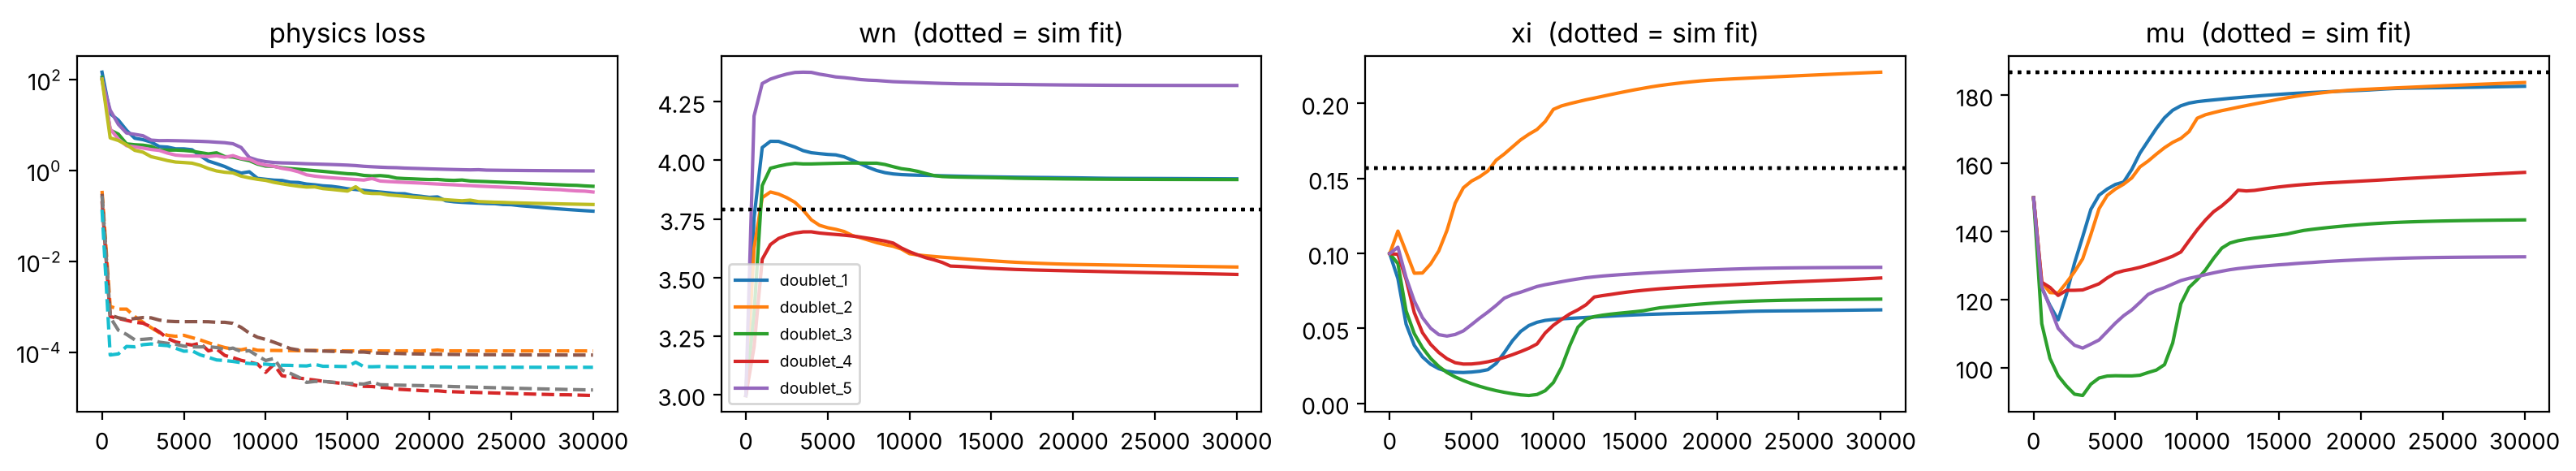

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3))
for n, r in pinn.items():
    h = r['history']
    ax[0].semilogy(h.epoch, h.physics); ax[0].set_title('physics loss')
    ax[0].semilogy(h.epoch, h.data, '--')
    for i, k in enumerate(['wn', 'xi', 'mu']):
        ax[i + 1].plot(h.epoch, h[k], label=n.replace('.csv', '')); ax[i + 1].axhline(sim['p'][k], color='k', ls=':')
        ax[i + 1].set_title(k + '  (dotted = sim fit)')
ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()

## 5. Results: constants and test-flight match

In [7]:
pinn_mean = {k: np.mean([r['p'][k] for r in pinn.values()]) for k in ['wn', 'xi', 'mu', 'th0']}
pinn_std = {k: np.std([r['p'][k] for r in pinn.values()]) for k in ['wn', 'xi', 'mu']}
sim_std = {k: np.std([r['p'][k] for r in sim_each.values()]) for k in ['wn', 'xi', 'mu']}
ft = flights[TEST]
y_sim = run_ivp(sim['p'], ft)[0]; y_pinn = run_ivp(pinn_mean, ft)[0]; y_antx = run_ivp(dict(ANTX, th0=0.0), ft)[0]
table = pd.DataFrame({
    'ANT-X published': [ANTX['wn'], ANTX['xi'], ANTX['mu'], '-', vaf(ft.theta.values, y_antx), '-'],
    'Sim fit (5 flights)': [sim['p']['wn'], sim['p']['xi'], sim['p']['mu'],
                            f"wn {sim_std['wn']:.3f}, xi {sim_std['xi']:.3f}, mu {sim_std['mu']:.1f}",
                            vaf(ft.theta.values, y_sim), sim['time']],
    'Inverse PINN (mean of 5)': [pinn_mean['wn'], pinn_mean['xi'], pinn_mean['mu'],
                            f"wn {pinn_std['wn']:.3f}, xi {pinn_std['xi']:.3f}, mu {pinn_std['mu']:.1f}",
                            vaf(ft.theta.values, y_pinn), sum(r['time'] for r in pinn.values())],
}, index=['wn [rad/s]', 'xi [-]', 'mu [rad/s^2]', 'spread over flights (std)', 'test VAF [%]', 'train time [s]'])
table.to_csv('../results/batch1_2_doublet_constants.csv')
table

,ANT-X published,Sim fit (5 flights),Inverse PINN (mean of 5)
wn [rad/s],3.437,3.790606,3.843432
xi [-],0.0836,0.157075,0.105437
mu [rad/s^2],358.5,186.792564,159.925211
spread over flights (std),-,"wn 0.315, xi 0.076, mu 50.0","wn 0.295, xi 0.059, mu 20.6"
test VAF [%],0,98.802793,99.018712
train time [s],-,8.132128,442.838931


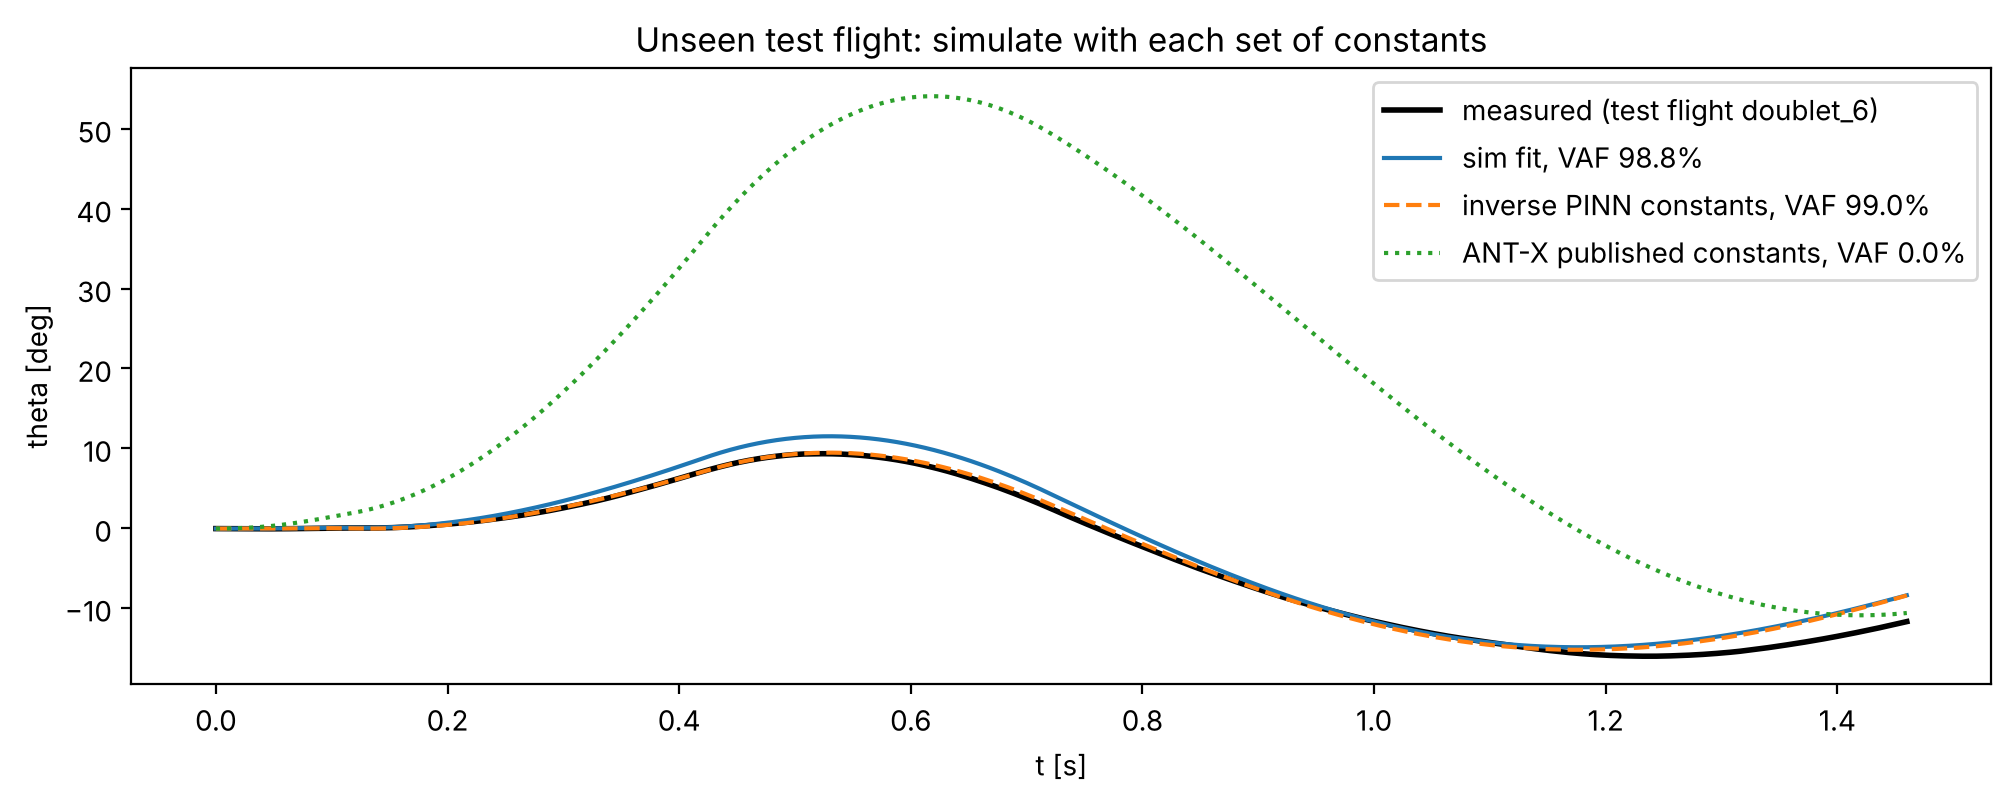

In [8]:
plt.figure(figsize=(12, 4))
plt.plot(ft.t, np.degrees(ft.theta), 'k', lw=2, label='measured (test flight doublet_6)')
plt.plot(ft.t, np.degrees(y_sim), label=f'sim fit, VAF {vaf(ft.theta.values, y_sim):.1f}%')
plt.plot(ft.t, np.degrees(y_pinn), '--', label=f'inverse PINN constants, VAF {vaf(ft.theta.values, y_pinn):.1f}%')
plt.plot(ft.t, np.degrees(y_antx), ':', label=f'ANT-X published constants, VAF {vaf(ft.theta.values, y_antx):.1f}%')
plt.xlabel('t [s]'); plt.ylabel('theta [deg]'); plt.legend(); plt.title('Unseen test flight: simulate with each set of constants')
plt.savefig('../figures/batch1_2_doublet_test_flight.png', dpi=120, bbox_inches='tight'); plt.show()

In [9]:
# impulse (motors off) constants on the hover test flight: are separate models needed?
p_imp = pd.read_csv('../results/batch1_2_constants.csv', index_col=0)['Sim fit (4 flights)']
p_imp = dict(wn=float(p_imp['wn [rad/s]']), xi=float(p_imp['xi [-]']), mu=float(p_imp['mu [rad/s^2]']), th0=0.0)
print('impulse sim-fit constants on doublet_6: VAF', round(vaf(ft.theta.values, run_ivp(p_imp, ft)[0]), 1), '%')

impulse sim-fit constants on doublet_6: VAF 51.8 %


## 6. What this shows
- Read the table: how close the inverse PINN constants are to the simulation fit, and the spread over the 4 flights.
- If the impulse (motors off) constants do badly here, hover and motors-off need separate models.
- Next (Batch 3): PINC, a network that takes (state, M, dt) and gives the next state, with these constants in its physics loss.